# Final comparison: TF-IDF and LR vs BERT-base vs DeBERTa-v3-base
This notebook doesn't train anything. It loads the results saved by the baseline, BERT and DeBERTa notebooks and compares them side by side.

What we compare:
1. Accuracy and F1 on each dataset (in-domain)
2. The key cross-test: trained on QQP, tested on PAWS
3. The full transfer matrix of BERT vs DeBERTa
4. McNemar's test: is the difference between BERT and DeBERTa real or just luck?
5. Picking the winner using dev F1 (never the test set)
6. Accuracy on PAWS pairs with high word overlap
7. The debiased DeBERTa compared with the other QQP-trained models

In [1]:
import os, re, glob, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import binomtest
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix

# folders on my laptop 
PROJECT = "D:/Dummy/NLP_Project"
BASELINE_DIR = f"{PROJECT}/paraphrase"            
BERT_DIR = f"{PROJECT}/bert_export"               
BERT_RESULTS = f"{PROJECT}/bert_base_results"          
DEBERTA_DIR = f"{PROJECT}/deberta_export"         

FIG = f"{PROJECT}/comparison_figures"
os.makedirs(FIG, exist_ok=True)

SEEDS = [42, 43, 44, 45, 46]
ORDER = ["mrpc", "qqp", "paws"]

In [2]:
# checking that every file needed is present
needed = [f"{BASELINE_DIR}/results_baseline.csv",
          f"{BERT_DIR}/bert_transfer_all_runs.csv",
          f"{DEBERTA_DIR}/deberta_transfer_all_runs.csv",
          f"{DEBERTA_DIR}/deberta_dev_f1.csv"]
for tr in ORDER:
    for te in ORDER:
        needed.append(f"{BERT_DIR}/preds/bert_{tr}_to_{te}.csv")
        needed.append(f"{DEBERTA_DIR}/preds/deberta_{tr}_to_{te}.csv")

missing = [f for f in needed if not os.path.exists(f)]
print(f"{len(needed) - len(missing)} of {len(needed)} files found")
for f in missing:
    print("MISSING:", f)

22 of 22 files found


## Load the results
- **Baseline:** We report a single run for each setting. Since logistic regression is deterministic, repeated runs give the same result.
- **BERT and DeBERTa:** We fine-tune each model with 5 random seeds and evaluate every run on all three test sets. This gives us the transfer matrix.
- **Majority guess:** It is the accuracy of always predicting the most common label. It is the minimum any model should reach, so a model that does    not clearly beat it has not learned much.

In [3]:
# Baseline results. Logistic regression is deterministic, so we only need one run per setting.
baseline = pd.read_csv(f"{BASELINE_DIR}/results_baseline.csv")

# BERT and DeBERTa: one row per (train set, test set, seed)
bert_x = pd.read_csv(f"{BERT_DIR}/bert_transfer_all_runs.csv")
deb_x = pd.read_csv(f"{DEBERTA_DIR}/deberta_transfer_all_runs.csv")

# Tag each row with its model name so both models can go into one table.
bert_x["model"] = "BERT-base"
deb_x["model"] = "DeBERTa-v3-base"
xfer = pd.concat([bert_x, deb_x], ignore_index=True)

# Majority-class accuracy for each test set: the score from always guessing the most common label.
# It depends only on the test set, so we take the first value in each group.
majority = xfer.groupby("test")["majority_acc"].first()

# Sanity check: 3 train sets x 3 test sets x 5 seeds = 45 runs per model.
print("BERT rows:", len(bert_x), "| DeBERTa rows:", len(deb_x), "(expected 45 each)")
print(majority.round(3))

BERT rows: 45 | DeBERTa rows: 45 (expected 45 each)
test
mrpc    0.684
paws    0.558
qqp     0.633
Name: majority_acc, dtype: float64


## Main results table
Accuracy and F1 for every model on the three in-domain settings and the QQP -> PAWS cross-test. BERT and DeBERTa are shown as mean ± std over 5 seeds.

In [4]:
def mean_std(values):
    """
    Summarise several runs as 'mean ± std'.
    ddof=1 uses the sample std, because our 5 seeds are only a small sample of all possible runs.
    """
    return f"{np.mean(values):.3f} ± {np.std(values, ddof=1):.3f}"

# Settings shown in the main table: the three in-domain settings plus QQP → PAWS, our main cross-dataset test.
settings = [("mrpc", "mrpc"), ("qqp", "qqp"), ("paws", "paws"), ("qqp", "paws")]

rows = []
for tr, te in settings:
    name = f"{tr.upper()} → {te.upper()}"

    # majority guess: only predicts one label, so F1 is not meaningful here.
    rows.append({"setting": name, "model": "Majority guess",
                 "accuracy": f"{majority[te]:.3f}", "F1": "-"})

    # baseline (single run, so no ± std)
    b = baseline[(baseline.train == tr) & (baseline.test == te)]
    if len(b) > 0:
        rows.append({"setting": name, "model": "TF-IDF + LR",
                     "accuracy": f"{b.accuracy.iloc[0]:.3f}", "F1": f"{b.f1.iloc[0]:.3f}"})

    # BERT and DeBERTa: Each is reported as mean ± std over its 5 seeds.
    for model in ["BERT-base", "DeBERTa-v3-base"]:
        sub = xfer[(xfer.model == model) & (xfer.train == tr) & (xfer.test == te)]
        rows.append({"setting": name, "model": model,
                     "accuracy": mean_std(sub.acc), "F1": mean_std(sub.f1)})

# Put everything into one table and save it.
main_table = pd.DataFrame(rows)
main_table.to_csv(f"{PROJECT}/comparison_main_table.csv", index=False)
main_table

,setting,model,accuracy,F1
0,MRPC → MRPC,Majority guess,0.684,-
1,MRPC → MRPC,TF-IDF + LR,0.750,0.830
2,MRPC → MRPC,BERT-base,0.805 ± 0.012,0.867 ± 0.005
3,MRPC → MRPC,DeBERTa-v3-base,0.880 ± 0.006,0.912 ± 0.004
4,QQP → QQP,Majority guess,0.633,-
5,QQP → QQP,TF-IDF + LR,0.778,0.676
6,QQP → QQP,BERT-base,0.855 ± 0.005,0.813 ± 0.005
7,QQP → QQP,DeBERTa-v3-base,0.885 ± 0.002,0.849 ± 0.002
8,PAWS → PAWS,Majority guess,0.558,-
9,PAWS → PAWS,TF-IDF + LR,0.570,0.626


## The key cross-test: trained on QQP, tested on PAWS
F1 and recall can look fine even when a model just says "paraphrase" to almost everything. So here we also look at:
- **specificity:** share of real non-paraphrases the model gets right. On PAWS, most non-paraphrase pairs share nearly all their words, so a model that relies on word overlap calls them paraphrases and gets low specificity.
- **predicted paraphrase:** share of pairs the model calls "paraphrase". The true share is 0.442, so a rate well above that means the model is over-predicting paraphrases.
- **AUC:** how well the model's scores separate the 2 classes, without depending on the 0.5 decision threshold. An AUC of 0.5 is no better than random guessing, and 1.0 is perfect separation.

In [5]:
def load_preds(model, tr, te):
    """
    Load the predictions for one train -> test setting.
    Returns the prediction file (true labels and averaged probability) and a list of each seed's
    predicted labels. The baseline has only one run, so its list has just one entry.    
    """
    if model == "baseline":
        df = pd.read_csv(f"{BASELINE_DIR}/preds/baseline_{tr}_to_{te}.csv", keep_default_na=False)
        return df, [df["pred"].values]          
    folder = BERT_DIR if model == "bert" else DEBERTA_DIR
    df = pd.read_csv(f"{folder}/preds/{model}_{tr}_to_{te}.csv", keep_default_na=False)
    seed_preds = [df[f"pred_s{s}"].values for s in SEEDS]
    return df, seed_preds

def specificity(y, p):
    """
    Share of true non-paraphrases that the model correctly labels as 'not paraphrase'.
    """
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    return tn / (tn + fp)

# Main cross-dataset test: train on QQP, test on PAWS.
# Accuracy, specificity and predicted paraphrase rate are computed separately for each seed and then averaged.
# AUC is computed once, from the probability averaged over all seeds.
rows = []
for model, label in [("baseline", "TF-IDF + LR"), ("bert", "BERT-base"), ("deberta", "DeBERTa-v3-base")]:
    df, seed_preds = load_preds(model, "qqp", "paws")
    y = df["label"].values
    acc = [accuracy_score(y, p) for p in seed_preds]
    spec = [specificity(y, p) for p in seed_preds]
    para = [p.mean() for p in seed_preds]   # share of pairs labelled "paraphrase"
    
    # Show "± std" only for models with several runs. The baseline has just one run, so it gets a single number.
    sd = lambda v: f" ± {np.std(v, ddof=1):.3f}" if len(v) > 1 else ""
    rows.append({"model": label,
                 "accuracy": f"{np.mean(acc):.3f}{sd(acc)}",
                 "specificity": f"{np.mean(spec):.3f}{sd(spec)}",
                 "predicted paraphrase": f"{np.mean(para):.3f}{sd(para)}",
                 "AUC (of averaged prob)": f"{roc_auc_score(y, df['prob']):.3f}"})

cross = pd.DataFrame(rows)
print("Trained on QQP, tested on PAWS (majority guess =", round(majority["paws"], 3), ")")
cross

Trained on QQP, tested on PAWS (majority guess = 0.558 )


,model,accuracy,specificity,predicted paraphrase,AUC (of averaged prob)
0,TF-IDF + LR,0.469,0.124,0.888,0.500
1,BERT-base,0.485 ± 0.017,0.276 ± 0.130,0.735 ± 0.130,0.536
2,DeBERTa-v3-base,0.524 ± 0.042,0.184 ± 0.084,0.877 ± 0.052,0.761


The AUC here comes from the probability averaged over the 5 seeds, so it can come out slightly different from the per-seed average AUC in the DeBERTa notebook (0.731).

## Transfer matrix: BERT vs DeBERTa
Each row shows the dataset the model was trained on, and each column shows the dataset it was tested on. The diagonal cells are in-domain results, where the model is trained and tested on the same dataset. Every other cell is a cross-dataset result, which shows how well the model transfers to data it wasn't trained on. The third plot shows the difference (DeBERTa minus BERT) in each cell. Green means DeBERTa does better there, and red means BERT does.

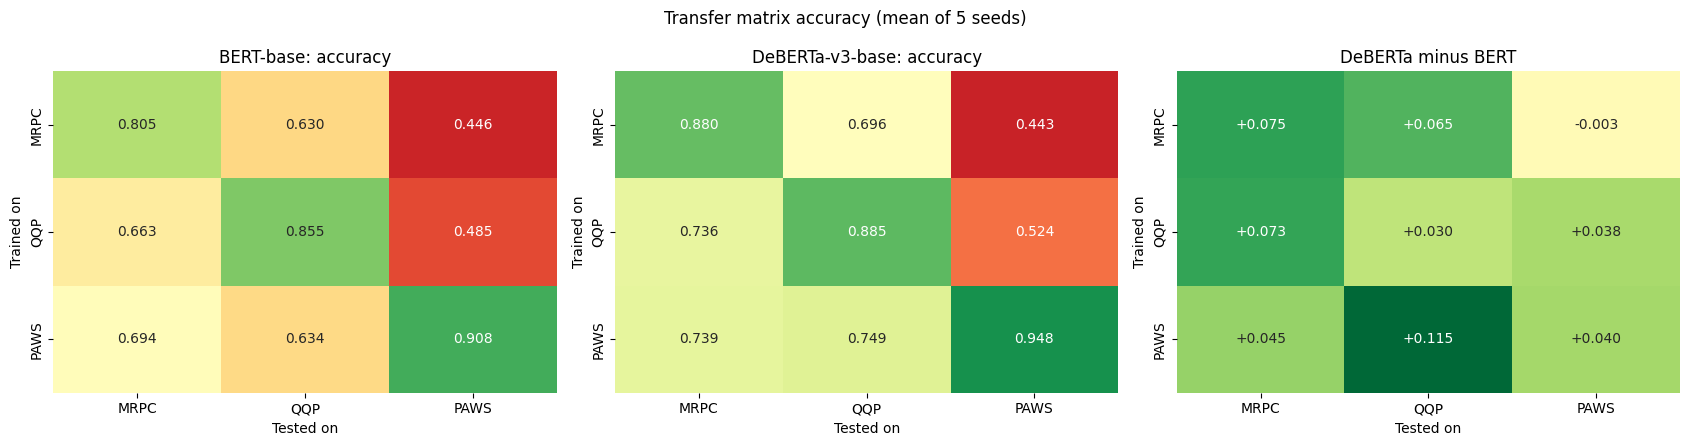

In [6]:
# BERT accuracy, DeBERTa accuracy, and their difference, side by side.
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# One heatmap per model. Each cell is the mean accuracy over 5 seeds.
for ax, model in zip(axes[:2], ["BERT-base", "DeBERTa-v3-base"]):
    acc = xfer[xfer.model == model].pivot_table(index="train", columns="test", values="acc").loc[ORDER, ORDER]
    
    # Same colour range for both models so they can be compared.
    sns.heatmap(acc, annot=True, fmt=".3f", cmap="RdYlGn", vmin=0.4, vmax=1, cbar=False, ax=ax,
                xticklabels=[o.upper() for o in ORDER], yticklabels=[o.upper() for o in ORDER])
    ax.set_title(f"{model}: accuracy")
    ax.set_xlabel("Tested on"); ax.set_ylabel("Trained on")

# DeBERTa minus BERT: green = DeBERTa better, red = BERT better
b = xfer[xfer.model == "BERT-base"].pivot_table(index="train", columns="test", values="acc").loc[ORDER, ORDER]
d = xfer[xfer.model == "DeBERTa-v3-base"].pivot_table(index="train", columns="test", values="acc").loc[ORDER, ORDER]
sns.heatmap(d - b, annot=True, fmt="+.3f", cmap="RdYlGn", center=0, vmin=-0.1, vmax=0.1, cbar=False, ax=axes[2],
            xticklabels=[o.upper() for o in ORDER], yticklabels=[o.upper() for o in ORDER])
axes[2].set_title("DeBERTa minus BERT")
axes[2].set_xlabel("Tested on"); axes[2].set_ylabel("Trained on")

# Save and show the figure
plt.suptitle("Transfer matrix accuracy (mean of 5 seeds)")
plt.tight_layout(); plt.savefig(f"{FIG}/transfer_bert_vs_deberta.png", dpi=200); plt.show()

## All models in one chart
The grey bar is the majority guess. Any bar at or below it means the model is doing no better than always guessing the most common label.

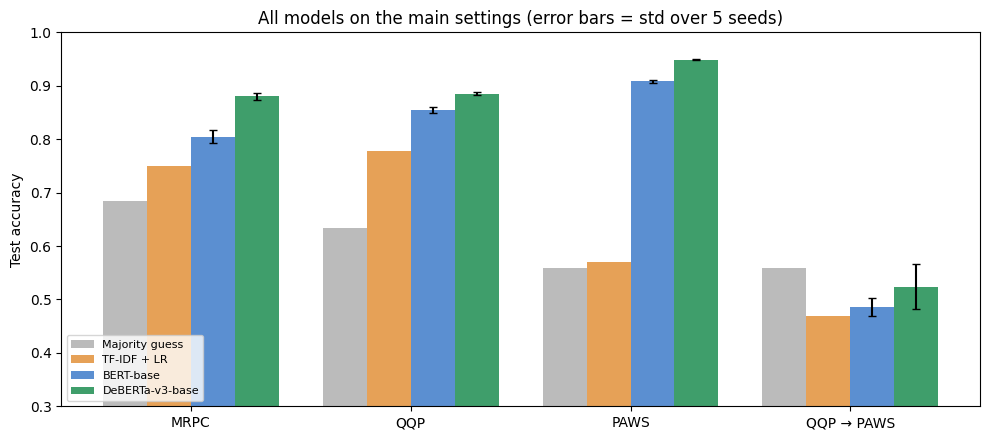

In [7]:
labels = ["MRPC", "QQP", "PAWS", "QQP → PAWS"]
x = np.arange(len(labels))
width = 0.2

# accuracy of each model in each setting
maj, base, bert_m, bert_s, deb_m, deb_s = [], [], [], [], [], []
for tr, te in settings:
    maj.append(majority[te])
    b = baseline[(baseline.train == tr) & (baseline.test == te)]
    base.append(b.accuracy.iloc[0] if len(b) else np.nan)   # leave a gap if the baseline is missing
    sub_b = xfer[(xfer.model == "BERT-base") & (xfer.train == tr) & (xfer.test == te)].acc
    sub_d = xfer[(xfer.model == "DeBERTa-v3-base") & (xfer.train == tr) & (xfer.test == te)].acc
    bert_m.append(sub_b.mean()); bert_s.append(sub_b.std(ddof=1))
    deb_m.append(sub_d.mean()); deb_s.append(sub_d.std(ddof=1))

# Grouped bar chart: one group per setting, one bar per model.
# Error bars show the spread across seeds, so only BERT and DeBERTa have them.
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(x - 1.5 * width, maj, width, label="Majority guess", color="#bbbbbb")
ax.bar(x - 0.5 * width, base, width, label="TF-IDF + LR", color="#e6a157")
ax.bar(x + 0.5 * width, bert_m, width, yerr=bert_s, capsize=3, label="BERT-base", color="#5b8fd1")
ax.bar(x + 1.5 * width, deb_m, width, yerr=deb_s, capsize=3, label="DeBERTa-v3-base", color="#3f9e6b")
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylabel("Test accuracy"); ax.set_ylim(0.3, 1.0)
ax.set_title("All models on the main settings (error bars = std over 5 seeds)")
ax.legend(fontsize=8, loc="lower left")

# Save and show the figure.
plt.tight_layout(); plt.savefig(f"{FIG}/accuracy_all_models.png", dpi=200); plt.show()

## McNemar's test: is DeBERTa really better than BERT?
A small accuracy gap between two models could just be chance. McNemar's test checks this by looking only at the test pairs where the two models disagree:
- **b** = pairs only BERT gets right
- **c** = pairs only DeBERTa gets right

If the two models were equally good, b and c should be roughly equal, like heads and tails from a fair coin. A p-value below 0.05 means the gap between b and c is unlikely to be due to chance alone. For each model we use the majority vote across its 5 seeds (the `pred` column).

In [8]:
def mcnemar(y, pred_a, pred_b):
    """ 
    Exact McNemar's test between two models. Returns b, c and the p-value.
    """
    # Which pairs each model gets right.
    right_a = pred_a == y
    right_b = pred_b == y
    
    # Count only the pairs where the models disagree.
    b = int(np.sum(right_a & ~right_b)) # only model A is right
    c = int(np.sum(~right_a & right_b)) # only model B is right
    
    # If both models were equally good, each disagreement would be a fair coin flip,
    # so we test b out of (b + c) against a 50/50 split. With no disagreements there's nothing to test, so p = 1.
    p = binomtest(b, b + c, 0.5).pvalue if (b + c) > 0 else 1.0
    return b, c, p

In [9]:
# Run McNemar's test for BERT vs DeBERTa in each main setting.
rows = []
for tr, te in settings:
    bert_df, _ = load_preds("bert", tr, te)
    deb_df, _ = load_preds("deberta", tr, te)

    # both files must list the same test pairs in the same order
    assert (bert_df["sentence1"].values == deb_df["sentence1"].values).all()
    y = bert_df["label"].values

    # Compare each model's majority vote across its 5 seeds (the "pred" column)
    only_bert, only_deb, p = mcnemar(y, bert_df["pred"].values, deb_df["pred"].values)
    rows.append({"setting": f"{tr.upper()} → {te.upper()}",
                 "BERT acc": round(accuracy_score(y, bert_df["pred"]), 3),
                 "DeBERTa acc": round(accuracy_score(y, deb_df["pred"]), 3),
                 "only BERT right": only_bert, "only DeBERTa right": only_deb,
                 "p-value": f"{p:.2g}", "significant (p < 0.05)": p < 0.05})

mcnemar_table = pd.DataFrame(rows)
mcnemar_table.to_csv(f"{PROJECT}/comparison_mcnemar.csv", index=False)
mcnemar_table

,setting,BERT acc,DeBERTa acc,only BERT right,only DeBERTa right,p-value,significant (p < 0.05)
0,MRPC → MRPC,0.824,0.880,16,39,0.0027,True
1,QQP → QQP,0.864,0.888,193,315,6.9e-08,True
2,PAWS → PAWS,0.918,0.951,132,391,9.2e-31,True
3,QQP → PAWS,0.480,0.516,757,1043,1.7e-11,True


## Pick the winner
Following the plan, the encoder that goes on to be compared with the LLM is chosen on dev F1, never on the test set. If the two are within 0.005 of each other, the QQP -> PAWS cross-test (AUC) breaks the tie.

Dev F1 of both the models

In [10]:
# DeBERTa: best dev F1 for each run, already saved by the DeBERTa notebook.
deb_dev = pd.read_csv(f"{DEBERTA_DIR}/deberta_dev_f1.csv")

# BERT: best dev F1 from the dev curve saved in each run's metrics file
bert_rows = []
for ds in ORDER:
    for s in SEEDS:
        path = f"{BERT_RESULTS}/bert_{ds}_s{s}_metrics.json"
        if os.path.exists(path):
            curve = json.load(open(path))["dev_curve"]
            bert_rows.append({"dataset": ds, "seed": s, "best_dev_f1": max(c["dev_f1"] for c in curve)})
bert_dev = pd.DataFrame(bert_rows)

# Sanity check: 3 datasets x 5 seeds = 15 runs.
print("BERT dev F1 files found:", len(bert_dev), "of 15")

#  Dev table: mean ± std of the best dev F1 for each dataset and model.
rows = []
for ds in ORDER:
    row = {"dataset": ds.upper()}
    for name, dev in [("BERT-base", bert_dev), ("DeBERTa-v3-base", deb_dev)]:
        v = dev[dev.dataset == ds]["best_dev_f1"] if len(dev) else []
        
        # Show mean ± std if we have at least 2 runs, otherwise mark the cell as "missing".
        row[name] = mean_std(v) if len(v) > 1 else "missing"
    rows.append(row)

dev_table = pd.DataFrame(rows)
dev_table

BERT dev F1 files found: 15 of 15


,dataset,BERT-base,DeBERTa-v3-base
0,MRPC,0.838 ± 0.007,0.912 ± 0.004
1,QQP,0.801 ± 0.004,0.844 ± 0.004
2,PAWS,0.912 ± 0.004,0.951 ± 0.002


In [11]:
# Pick the final model using the rule from our plan that is higher average dev F1 wins.
# If the two are within 0.005, QQP -> PAWS AUC breaks the tie.
if len(bert_dev) == 15: # only decide once all 15 BERT runs are loaded
    # Average over seeds first, then over the 3 datasets, so each dataset counts equally.
    bert_avg = bert_dev.groupby("dataset")["best_dev_f1"].mean().mean()
    deb_avg = deb_dev.groupby("dataset")["best_dev_f1"].mean().mean()
    print(f"Average dev F1 over the 3 datasets: BERT {bert_avg:.3f} | DeBERTa {deb_avg:.3f}")

    if abs(bert_avg - deb_avg) < 0.005:
        # Too close to call, so use the mean QQP -> PAWS AUC over 5 seeds.
        b = xfer[(xfer.model == "BERT-base") & (xfer.train == "qqp") & (xfer.test == "paws")].auc.mean()
        d = xfer[(xfer.model == "DeBERTa-v3-base") & (xfer.train == "qqp") & (xfer.test == "paws")].auc.mean()
        winner = "DeBERTa-v3-base" if d > b else "BERT-base"
        print(f"Dev F1 is a tie, QQP -> PAWS AUC decides: BERT {b:.3f} | DeBERTa {d:.3f}")
    else:
        winner = "DeBERTa-v3-base" if deb_avg > bert_avg else "BERT-base"
    print("Winner:", winner)
else:
    print("BERT dev F1 files are missing, so the winner can't be picked from dev F1 yet")

Average dev F1 over the 3 datasets: BERT 0.851 | DeBERTa 0.902
Winner: DeBERTa-v3-base


## Where do the models go wrong on PAWS?
To find where the models struggle, we split the PAWS test set by how many words the two sentences share and check accuracy on the hardest groups:
- **Overlap ≥ 0.9:** the two sentences share almost all of their words.
- **Same words, new order:** both sentences use exactly the same words, just rearranged (E.g. two names swapped).

A bag-of-words model ignores word order, so it sees the two sentences in a "same words, new order" pair as identical, and it has very little to go on when overlap is ≥ 0.9. Doing well on these groups is a sign that a model is actually using word order, not just word overlap.

Accuracy by overlap

In [12]:
# Helpers for splitting the PAWS test pairs by how many words the two sentences share.
def jaccard(s1, s2):
    """
    Word overlap between two sentences: shared words divided by all distinct words (0 to 1).
    """
    # Lowercase each sentence and turn it into a set of words, ignoring punctuation.
    w1 = set(re.findall(r"\w+", s1.lower()))
    w2 = set(re.findall(r"\w+", s2.lower()))
    
    # If both sentences are empty, return 0 to avoid dividing by zero.
    return len(w1 & w2) / len(w1 | w2) if (w1 | w2) else 0.0

def same_words(s1, s2):
    """
    True if both sentences use exactly the same words (with the same counts), in any order.
    """
    # Sorting the word lists ignores order but still counts repeated words.
    return sorted(re.findall(r"\w+", s1.lower())) == sorted(re.findall(r"\w+", s2.lower()))

In [13]:
# Accuracy on the hardest PAWS pairs, for models trained on PAWS (in-domain) and on QQP (cross-dataset).
rows = []
for tr in ["paws", "qqp"]:
    for model, label in [("baseline", "TF-IDF + LR"), ("bert", "BERT-base"), ("deberta", "DeBERTa-v3-base")]:
        # The baseline should be in every row, so stop if its file is missing.
        if model == "baseline":
            assert os.path.exists(f"{BASELINE_DIR}/preds/baseline_{tr}_to_paws.csv"), f"missing baseline file for {tr} → paws"
        df, _ = load_preds(model, tr, "paws")
        
        # Which pairs the model gets right (majority vote for BERT/DeBERTa)
        correct = (df["pred"] == df["label"]).values
        
        # Mark each pair as "same words" and compute its word overlap.
        same = np.array([same_words(a, b) for a, b in zip(df.sentence1, df.sentence2)])
        jac = np.array([jaccard(a, b) for a, b in zip(df.sentence1, df.sentence2)])
        
        # Accuracy on all pairs, then on the two hard groups
        rows.append({"trained on": tr.upper(), "model": label,
                     "all pairs": round(correct.mean(), 3),
                     "overlap ≥ 0.9": round(correct[jac >= 0.9].mean(), 3),
                     "same words, new order": round(correct[same].mean(), 3)})

# Group sizes, so that we know how many pairs each accuracy is based on.
print("Accuracy on the PAWS test set by word overlap (5-seed vote for BERT/DeBERTa)")
print("pairs with same words:", int(same.sum()), "| pairs with overlap ≥ 0.9:", int((jac >= 0.9).sum()))
pd.DataFrame(rows)

Accuracy on the PAWS test set by word overlap (5-seed vote for BERT/DeBERTa)
pairs with same words: 853 | pairs with overlap ≥ 0.9: 3606


,trained on,model,all pairs,overlap ≥ 0.9,"same words, new order"
0,PAWS,TF-IDF + LR,0.570,0.565,0.497
1,PAWS,BERT-base,0.918,0.933,0.937
2,PAWS,DeBERTa-v3-base,0.951,0.958,0.957
3,QQP,TF-IDF + LR,0.469,0.440,0.298
4,QQP,BERT-base,0.480,0.483,0.419
5,QQP,DeBERTa-v3-base,0.516,0.524,0.455


## Adding the debiased DeBERTa
In the debiased notebook, we trained DeBERTa on QQP again, but this time each training pair was weighted by how easily the word-overlap model could solve it. Since this model was only trained on QQP, we compare it here with the other QQP-trained models on all three test sets. Nothing is retrained in this section; we only load the files saved by the debiased notebook.

In [14]:
# folder with the dev scores saved by the debiased notebook
DEBERTA_RESULTS = f"{PROJECT}/deberta_results"

# files we need for this section
needed = [f"{DEBERTA_DIR}/deberta_debias_transfer_all_runs.csv"]
for te in ORDER:
    needed.append(f"{DEBERTA_DIR}/preds/deberta_debias_qqp_to_{te}.csv")
for s in SEEDS:
    needed.append(f"{DEBERTA_RESULTS}/deberta_qqp_s{s}_debias_metrics.json")

# check that all of them are there
missing = []
for f in needed:
    if not os.path.exists(f):
        missing.append(f)

print(len(needed) - len(missing), "of", len(needed), "debiased files found")
for f in missing:
    print("MISSING:", f)

9 of 9 debiased files found


### All QQP-trained models side by side
Here we put all four QQP-trained models in one table: the baseline, BERT, standard DeBERTa and debiased DeBERTa. All the numbers are computed from the prediction files in the same way, so the comparison is fair. Accuracy, F1 and specificity are averaged over the 5 seeds, and AUC is computed from the probability averaged over the seeds, like in the QQP -> PAWS table earlier.

In [15]:
# the four models trained on QQP
qqp_models = [("baseline", "TF-IDF + LR"),
              ("bert", "BERT-base"),
              ("deberta", "DeBERTa-v3-base"),
              ("deberta_debias", "DeBERTa debiased")]

def fmt(values):
    # show mean ± std when there are several seeds, and a single number for the baseline
    if len(values) > 1:
        return f"{np.mean(values):.3f} ± {np.std(values, ddof=1):.3f}"
    return f"{values[0]:.3f}"

rows = []
for te in ["qqp", "paws", "mrpc"]:
    for model, label in qqp_models:
        df, seed_preds = load_preds(model, "qqp", te)
        y = df["label"].values

        # one score per seed
        acc, f1, spec = [], [], []
        for p in seed_preds:
            acc.append(accuracy_score(y, p))
            f1.append(f1_score(y, p))
            spec.append(specificity(y, p))

        rows.append({"setting": "QQP → " + te.upper(),
                     "model": label,
                     "accuracy": fmt(acc),
                     "F1": fmt(f1),
                     "specificity": fmt(spec),
                     "AUC (of averaged prob)": round(roc_auc_score(y, df["prob"]), 3)})

In [16]:
qqp_table = pd.DataFrame(rows)
qqp_table.to_csv(f"{PROJECT}/comparison_qqp_trained.csv", index=False)

print("Majority guess:", majority.round(3).to_dict())
qqp_table

Majority guess: {'mrpc': 0.684, 'paws': 0.558, 'qqp': 0.633}


,setting,model,accuracy,F1,specificity,AUC (of averaged prob)
0,QQP → QQP,TF-IDF + LR,0.778,0.676,0.863,0.852
1,QQP → QQP,BERT-base,0.855 ± 0.005,0.813 ± 0.005,0.854 ± 0.014,0.939
2,QQP → QQP,DeBERTa-v3-base,0.885 ± 0.002,0.849 ± 0.002,0.887 ± 0.015,0.956
3,QQP → QQP,DeBERTa debiased,0.870 ± 0.002,0.829 ± 0.005,0.877 ± 0.005,0.942
4,QQP → PAWS,TF-IDF + LR,0.469,0.601,0.124,0.500
5,QQP → PAWS,BERT-base,0.485 ± 0.017,0.559 ± 0.039,0.276 ± 0.130,0.536
6,QQP → PAWS,DeBERTa-v3-base,0.524 ± 0.042,0.639 ± 0.018,0.184 ± 0.084,0.761
7,QQP → PAWS,DeBERTa debiased,0.593 ± 0.036,0.667 ± 0.020,0.333 ± 0.066,0.735
8,QQP → MRPC,TF-IDF + LR,0.502,0.444,0.961,0.739
9,QQP → MRPC,BERT-base,0.663 ± 0.022,0.733 ± 0.041,0.616 ± 0.124,0.737


### QQP -> PAWS in one chart
This chart shows accuracy and specificity on PAWS for each QQP-trained model. The dashed line is the majority guess. Specificity is the more useful number here, because it shows how many of the PAWS trap pairs (non-paraphrases with high word overlap) each model actually rejects.

In [17]:
names = []
acc_mean, acc_std = [], []
spec_mean, spec_std = [], []

for model, label in qqp_models:
    df, seed_preds = load_preds(model, "qqp", "paws")
    y = df["label"].values

    acc, spec = [], []
    for p in seed_preds:
        acc.append(accuracy_score(y, p))
        spec.append(specificity(y, p))

    names.append(label)
    acc_mean.append(np.mean(acc))
    spec_mean.append(np.mean(spec))

    # the baseline has one run, so its error bar is 0
    if len(acc) > 1:
        acc_std.append(np.std(acc, ddof=1))
        spec_std.append(np.std(spec, ddof=1))
    else:
        acc_std.append(0)
        spec_std.append(0)

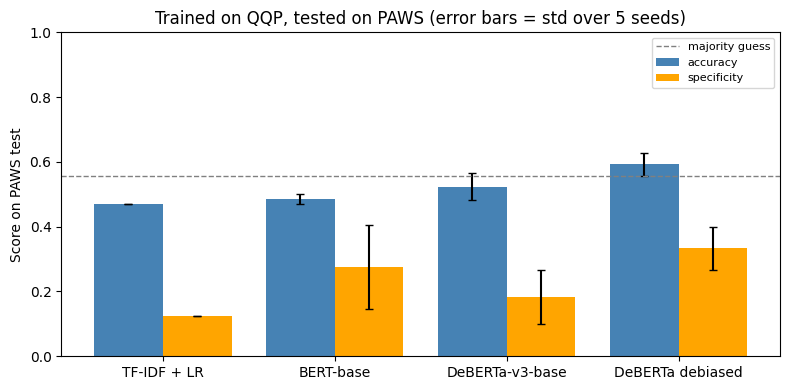

In [18]:
x = np.arange(len(names))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - 0.2, acc_mean, 0.4, yerr=acc_std, capsize=3, label="accuracy", color="steelblue")
ax.bar(x + 0.2, spec_mean, 0.4, yerr=spec_std, capsize=3, label="specificity", color="orange")

# dashed line for the majority guess
ax.axhline(majority["paws"], color="gray", linestyle="--", lw=1, label="majority guess")

ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylim(0, 1)
ax.set_ylabel("Score on PAWS test")
ax.set_title("Trained on QQP, tested on PAWS (error bars = std over 5 seeds)")
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(f"{FIG}/qqp_to_paws_with_debiased.png", dpi=200)
plt.show()

### McNemar's test: standard vs debiased DeBERTa
Debiasing made DeBERTa better on PAWS but slightly worse on QQP and MRPC. We use McNemar's test again to check whether these differences are real or could just be chance. Both models were trained on QQP, and for each one we use its combined 5-seed prediction (the `pred` column).

In [19]:
rows = []
for te in ["qqp", "paws", "mrpc"]:
    std_df, _ = load_preds("deberta", "qqp", te)
    deb_df, _ = load_preds("deberta_debias", "qqp", te)

    # make sure both files have the same test pairs in the same order
    assert (std_df["sentence1"].values == deb_df["sentence1"].values).all()
    y = std_df["label"].values

    only_std, only_deb, p = mcnemar(y, std_df["pred"].values, deb_df["pred"].values)

    rows.append({"setting": "QQP → " + te.upper(),
                 "standard acc": round(accuracy_score(y, std_df["pred"]), 3),
                 "debiased acc": round(accuracy_score(y, deb_df["pred"]), 3),
                 "only standard right": only_std,
                 "only debiased right": only_deb,
                 "p-value": f"{p:.2g}",
                 "significant (p < 0.05)": p < 0.05})

debias_mcnemar = pd.DataFrame(rows)
debias_mcnemar.to_csv(f"{PROJECT}/comparison_mcnemar_debiased.csv", index=False)
debias_mcnemar

,setting,standard acc,debiased acc,only standard right,only debiased right,p-value,significant (p < 0.05)
0,QQP → QQP,0.888,0.876,138,79,7.5e-05,True
1,QQP → PAWS,0.516,0.600,111,781,9.8e-125,True
2,QQP → MRPC,0.738,0.735,11,10,1,False


### PAWS accuracy by word overlap
We repeat the word-overlap breakdown from earlier, but only for the QQP-trained models, so we can see whether debiasing helps most on the pairs that share almost all their words.

In [20]:
rows = []
for model, label in qqp_models:
    df, _ = load_preds(model, "qqp", "paws")

    # which pairs the model got right
    correct = (df["pred"] == df["label"]).values

    # word overlap and "same words, new order" for every pair
    same = []
    jac = []
    for s1, s2 in zip(df["sentence1"], df["sentence2"]):
        same.append(same_words(s1, s2))
        jac.append(jaccard(s1, s2))
    same = np.array(same)
    jac = np.array(jac)

    rows.append({"model": label,
                 "all pairs": round(correct.mean(), 3),
                 "overlap ≥ 0.9": round(correct[jac >= 0.9].mean(), 3),
                 "same words, new order": round(correct[same].mean(), 3)})

print("Trained on QQP, tested on PAWS, split by word overlap")
pd.DataFrame(rows)

Trained on QQP, tested on PAWS, split by word overlap


,model,all pairs,overlap ≥ 0.9,"same words, new order"
0,TF-IDF + LR,0.469,0.440,0.298
1,BERT-base,0.480,0.483,0.419
2,DeBERTa-v3-base,0.516,0.524,0.455
3,DeBERTa debiased,0.600,0.633,0.641


### Which DeBERTa goes on to the LLM comparison?
To keep the choice fair, we use the same rule as before: the model with the higher dev F1 goes forward, and if the two are within 0.005 of each other, QQP -> PAWS AUC breaks the tie. Both models were trained on QQP, so we compare their QQP dev F1. We don't pick the model based on its PAWS test score, because that would mean choosing a model on the test set.

In [21]:
# QQP dev F1 of the standard DeBERTa (already loaded earlier)
std_dev = deb_dev[deb_dev.dataset == "qqp"]["best_dev_f1"].values

# QQP dev F1 of the debiased DeBERTa, one json file per seed
debias_dev = []
for s in SEEDS:
    res = json.load(open(f"{DEBERTA_RESULTS}/deberta_qqp_s{s}_debias_metrics.json"))
    debias_dev.append(res["best_dev_f1"])
debias_dev = np.array(debias_dev)

print("QQP dev F1  standard:", mean_std(std_dev), "| debiased:", mean_std(debias_dev))

if abs(std_dev.mean() - debias_dev.mean()) < 0.005:
    # too close to call, so we use the average QQP -> PAWS AUC over the 5 seeds
    debias_x = pd.read_csv(f"{DEBERTA_DIR}/deberta_debias_transfer_all_runs.csv")
    std_auc = xfer[(xfer.model == "DeBERTa-v3-base") & (xfer.train == "qqp") & (xfer.test == "paws")].auc.mean()
    deb_auc = debias_x[debias_x.test == "paws"].auc.mean()
    print(f"Dev F1 is a tie, so QQP -> PAWS AUC decides: standard {std_auc:.3f} | debiased {deb_auc:.3f}")

    if deb_auc > std_auc:
        choice = "DeBERTa debiased"
    else:
        choice = "DeBERTa-v3-base"
else:
    if debias_dev.mean() > std_dev.mean():
        choice = "DeBERTa debiased"
    else:
        choice = "DeBERTa-v3-base"

print("Goes forward under our rule:", choice)

QQP dev F1  standard: 0.844 ± 0.004 | debiased: 0.833 ± 0.006
Goes forward under our rule: DeBERTa-v3-base


## Summary
In this notebook we compared all our models on paraphrase identification and checked how well they transfer between datasets. Nothing was retrained here; every number comes from the files saved by the other notebooks.

**What we did**
- **Loaded the results** for the majority guess, the TF-IDF + LR baseline (one run), and BERT and DeBERTa (5 seeds each, trained and tested on every combination of MRPC, QQP and PAWS).
- **Built the main table** of accuracy and F1 for the three in-domain settings and the QQP -> PAWS cross-test.
- **Looked closely at QQP -> PAWS** using specificity, the share of pairs predicted as paraphrase, and AUC, to check whether a model was just calling everything a paraphrase.
- **Plotted the transfer matrix** for BERT and DeBERTa, and the difference between them in every train -> test setting.
- **Ran McNemar's test** to check whether the gaps between BERT and DeBERTa are real or just chance.
- **Picked the winner on dev F1**, as our plan says, with QQP -> PAWS AUC as the tie-break.
- **Broke down the PAWS errors by word overlap**, focusing on pairs that share almost all their words and pairs that use the same words in a different order.
- **Added the debiased DeBERTa** and compared it with the other QQP-trained models, both in a table and with McNemar's test.

**What we found**
- **DeBERTa is the strongest model.** It beats BERT in every main setting, all four gaps are significant, and it has the higher average dev F1 (0.902 vs 0.851). It is our winner and goes on to the LLM comparison.
- **Training data matters more than the encoder.** Trained on PAWS, both encoders handle word order well (DeBERTa gets 0.957 on pairs with the same words in a different order). Trained on QQP, every model leans on word overlap and stays near or below the PAWS majority guess of 0.558.
- **Debiasing helps, but only partly.** Debiased DeBERTa raised QQP -> PAWS accuracy from 0.524 to 0.593 and specificity from 0.184 to 0.333, and on same-words pairs it went from 0.455 to 0.641. The PAWS gain is significant. In exchange, QQP accuracy fell from 0.885 to 0.870, which is also significant. The small drop on MRPC is not significant.
- **The standard DeBERTa still goes forward.** Its QQP dev F1 is higher (0.844 vs 0.833), and we choose models on the dev set, not the test set. We still test the debiased model on the LLM-generated pairs, since those pairs check the same word-overlap shortcut it was trained to avoid.

**Limitations**
The debiased model's AUC on PAWS is lower than the standard model's (0.735 vs 0.761). So its gain mostly comes from labelling fewer pairs as paraphrase, not from separating the two classes better. Two-thirds of the PAWS trap pairs still fool it. Reweighting can only change how much each QQP pair counts. It cannot add the word-order examples that QQP lacks, which is why the PAWS-trained models (0.948) are still far ahead.

### Note: is the debiased DeBERTa better than the standard one?
It depends on what we test it on.

**Where it is better.** On QQP -> PAWS, the test built to catch the word-overlap shortcut, debiasing clearly helped. Accuracy rose from 0.524 to 0.593, which puts it above the majority guess of 0.558. Specificity rose from 0.184 to 0.333, so the model now rejects almost twice as many trap pairs. On pairs with the same words in a different order, accuracy went from 0.455 to 0.641. McNemar's test confirms the PAWS gain is real (781 pairs only the debiased model got right, against 111 for the standard one).

**Where it is slightly worse.** On QQP itself, accuracy dropped from 0.885 to 0.870, and this drop is also significant. On MRPC the two models are about the same; the difference there is not significant.

**Why it can't be better everywhere.** The weights don't give the model any new information. They only change how much each QQP pair counts during training. Word overlap is a genuinely useful clue on QQP, so when we push the model to rely on it less, it loses a little accuracy there. That trade only pays off on data like PAWS, where the same clue is misleading.

**This matches earlier work.** Debiasing papers report the same pattern. Schuster et al. (2019) found that reweighting improved BERT on their trap set while accuracy on the normal dev set went down, and Utama et al. (2020a) describe this exact trade-off between in-distribution and out-of-distribution performance. So the aim of debiasing is a model that is harder to fool with the shortcut, not a model that scores higher on every test set, and that is what we got.